---

<p align="center">
   <img src="img/pasaj.png" width="1000" height="300"> 
</p>

---
<div style="text-align: justify; line-height: 1.5; font-size: 18px;">


<h1 align="center"><b>  Número de Pasajeros Aéreos </b></h1>

---

El conjunto de datos AirPassengers registra el total mensual de pasajeros aéreos internacionales en miles entre 1949 y 1960 (144 observaciones), caracterizado por una clara tendencia creciente y una estacionalidad anual multiplicativa ($S=12$) con mayor amplitud en verano, por lo que es el ejemplo académico por excelencia para aplicar transformaciones logarítmicas y ajustar el célebre modelo **SARIMA** $(0,1,1) \times (0,1,1)_{12}$ .

</div>

---

## **Librerías y Carga de los Datos**

<div style="text-align: justify; line-height: 1.5; font-size: 18px;">


<h1 align="center"><b> </b></h1>

---

</div>

In [ ]:
# Instalar Librerías #
install.packages("stats")
install.packages("astsa")
install.packages("forecast")
install.packages("tseries")
install.packages("nortest")
install.packages("fBasics")
install.packages("car")
install.packages("MLmetrics")
install.packages("matrixcalc")
install.packages("aTSA")
install.packages("MASS")
install.packages("TSA")
install.packages("pastecs")

In [1]:
# Cargar Librerías #
library(stats)
library(astsa)
library(forecast)
library(tseries)
library(nortest)
library(fBasics)
library(car)
library(MLmetrics)
library(matrixcalc)
library(aTSA)
library(MASS)
library(TSA)
library(pastecs)

Warning message:
“package ‘forecast’ was built under R version 4.5.2”

Adjuntando el paquete: ‘forecast’


The following object is masked from ‘package:astsa’:

    gas


Registered S3 method overwritten by 'quantmod':
  method            from
  as.zoo.data.frame zoo 

Warning message:
“package ‘fBasics’ was built under R version 4.5.2”

Adjuntando el paquete: ‘fBasics’


The following object is masked from ‘package:astsa’:

    nyse


Cargando paquete requerido: carData


Adjuntando el paquete: ‘car’


The following object is masked from ‘package:fBasics’:

    densityPlot



Adjuntando el paquete: ‘MLmetrics’


The following object is masked from ‘package:base’:

    Recall



Adjuntando el paquete: ‘matrixcalc’


The following objects are masked from ‘package:fBasics’:

    vec, vech



Adjuntando el paquete: ‘aTSA’


The following objects are masked from ‘package:tseries’:

    adf.test, kpss.test, pp.test


The following object is masked from ‘package:forecast’:

    forecast


Th

In [4]:
# Leer el archivo pasaj.txt desde mi GitHub como un objeto ts() #
# pasaj <- ts(scan("/Users/duvancatano/Documents/App_Time_Series/Bases_Datos_Series/6_pasaj.txt"), start=1949, frequency=12)
pasaj <- ts(scan("/Users/duvancatano/Documents/Data_Time_Series_UdeA/data/pasaj.txt"), start=1949, frequency=12)
print(pasaj)

     Jan Feb Mar Apr May Jun Jul Aug Sep Oct Nov Dec
1949 112 118 132 129 121 135 148 148 136 119 104 118
1950 115 126 141 135 125 149 170 170 158 133 114 140
1951 145 150 178 163 172 178 199 199 184 162 146 166
1952 171 180 193 181 183 218 230 242 209 191 172 194
1953 196 196 236 235 229 243 264 272 237 211 180 201
1954 204 188 235 227 234 264 302 293 259 229 203 229
1955 242 233 267 269 270 315 364 347 312 274 237 278
1956 284 277 317 313 318 374 413 405 355 306 271 306
1957 315 301 356 348 355 422 465 467 404 347 305 336
1958 340 318 362 348 363 435 491 505 404 359 310 337
1959 360 342 406 396 420 472 548 559 463 407 362 405
1960 417 391 419 461 472 535 622 606 508 461 390 432


## **Análisis Descriptivo**

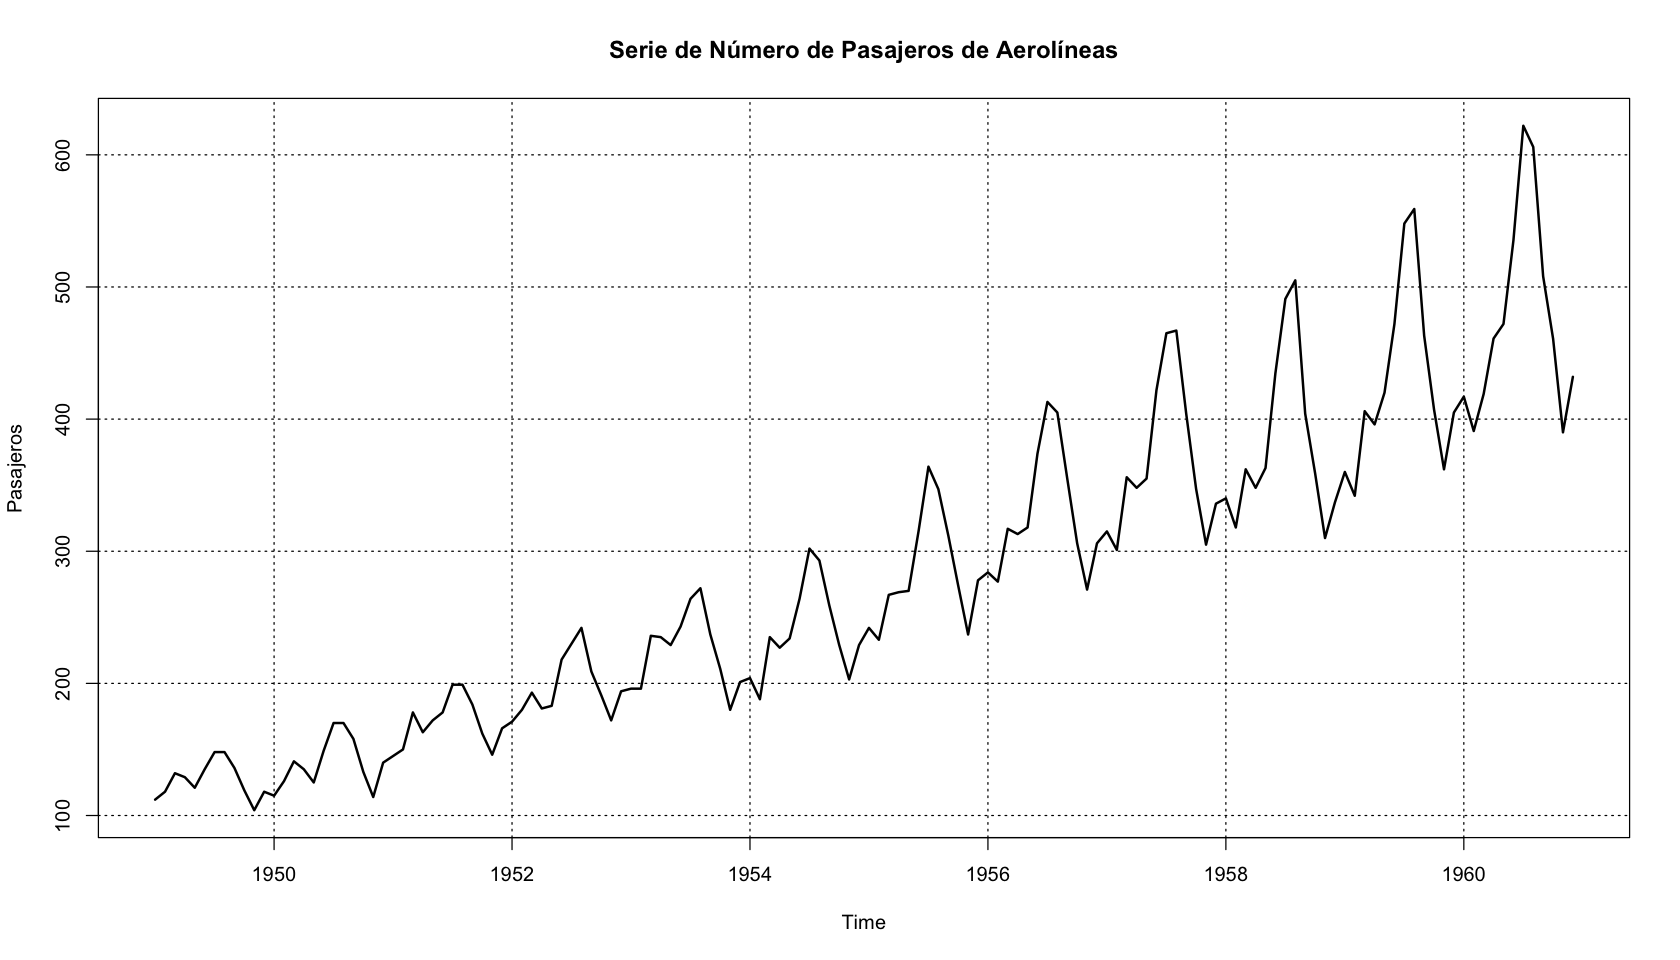

In [5]:
# Graficar la serie #
options(repr.plot.width=14, repr.plot.height=8)
ts.plot(pasaj, ylab="Pasajeros", main="Serie de Número de Pasajeros de Aerolíneas", lwd=2); grid(col = "black")

In [6]:
#install.packages("pastecs")
library(pastecs)

In [7]:
# Tabla Buys-Ballot library(pastecs)#
tb_bb = buysbal(pasaj, y=NULL, frequency=12, dateformat="m/Y")
tb_bb

,1,2,3,4,5,6,7,8,9,10,11,12
1949,112,118,132,129,121,135,148,148,136,119,104,118
1950,115,126,141,135,125,149,170,170,158,133,114,140
1951,145,150,178,163,172,178,199,199,184,162,146,166
1952,171,180,193,181,183,218,230,242,209,191,172,194
1953,196,196,236,235,229,243,264,272,237,211,180,201
1954,204,188,235,227,234,264,302,293,259,229,203,229
1955,242,233,267,269,270,315,364,347,312,274,237,278
1956,284,277,317,313,318,374,413,405,355,306,271,306
1957,315,301,356,348,355,422,465,467,404,347,305,336
1958,340,318,362,348,363,435,491,505,404,359,310,337


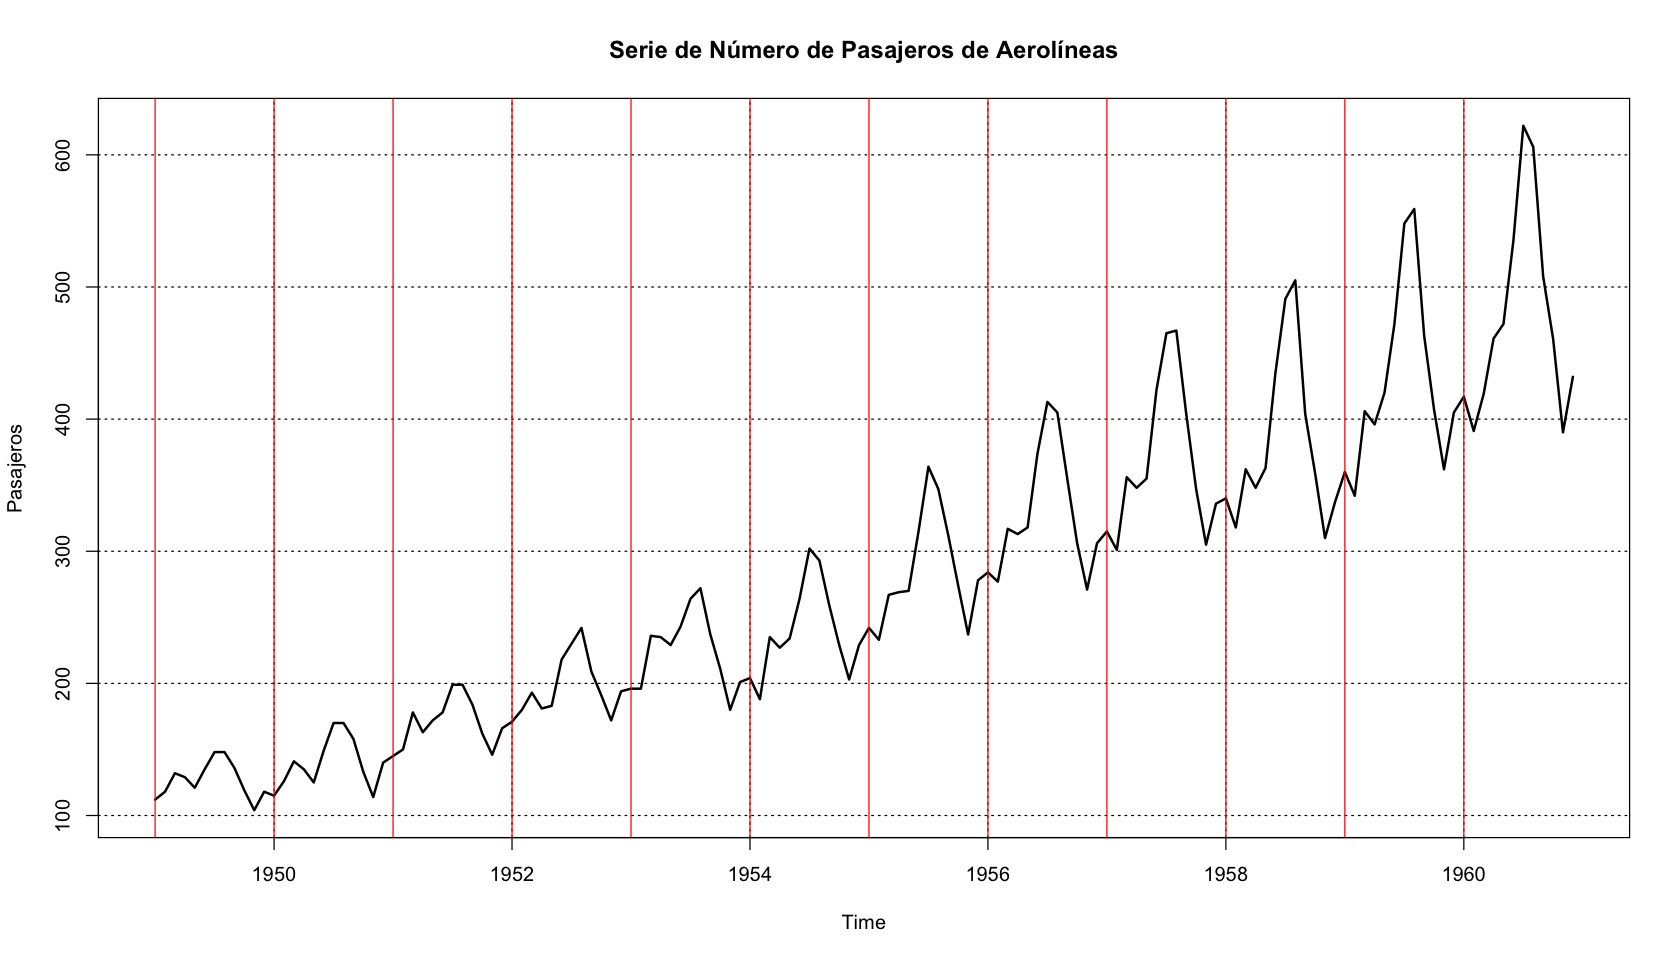

In [8]:
# Graficar la serie con periodos de cada 12 meses #
ts.plot(pasaj, ylab="Pasajeros", main="Serie de Número de Pasajeros de Aerolíneas", lwd=2); grid(col = "black")
abline(v=c(seq(1949,1960)), col="red")

## **Transformación de Box-Cox**

In [9]:
# Alternativa 1 (car) #
pasaj_BC = powerTransform(pasaj)
pasaj_BC

Estimated transformation parameter 
    pasaj 
0.1480226 

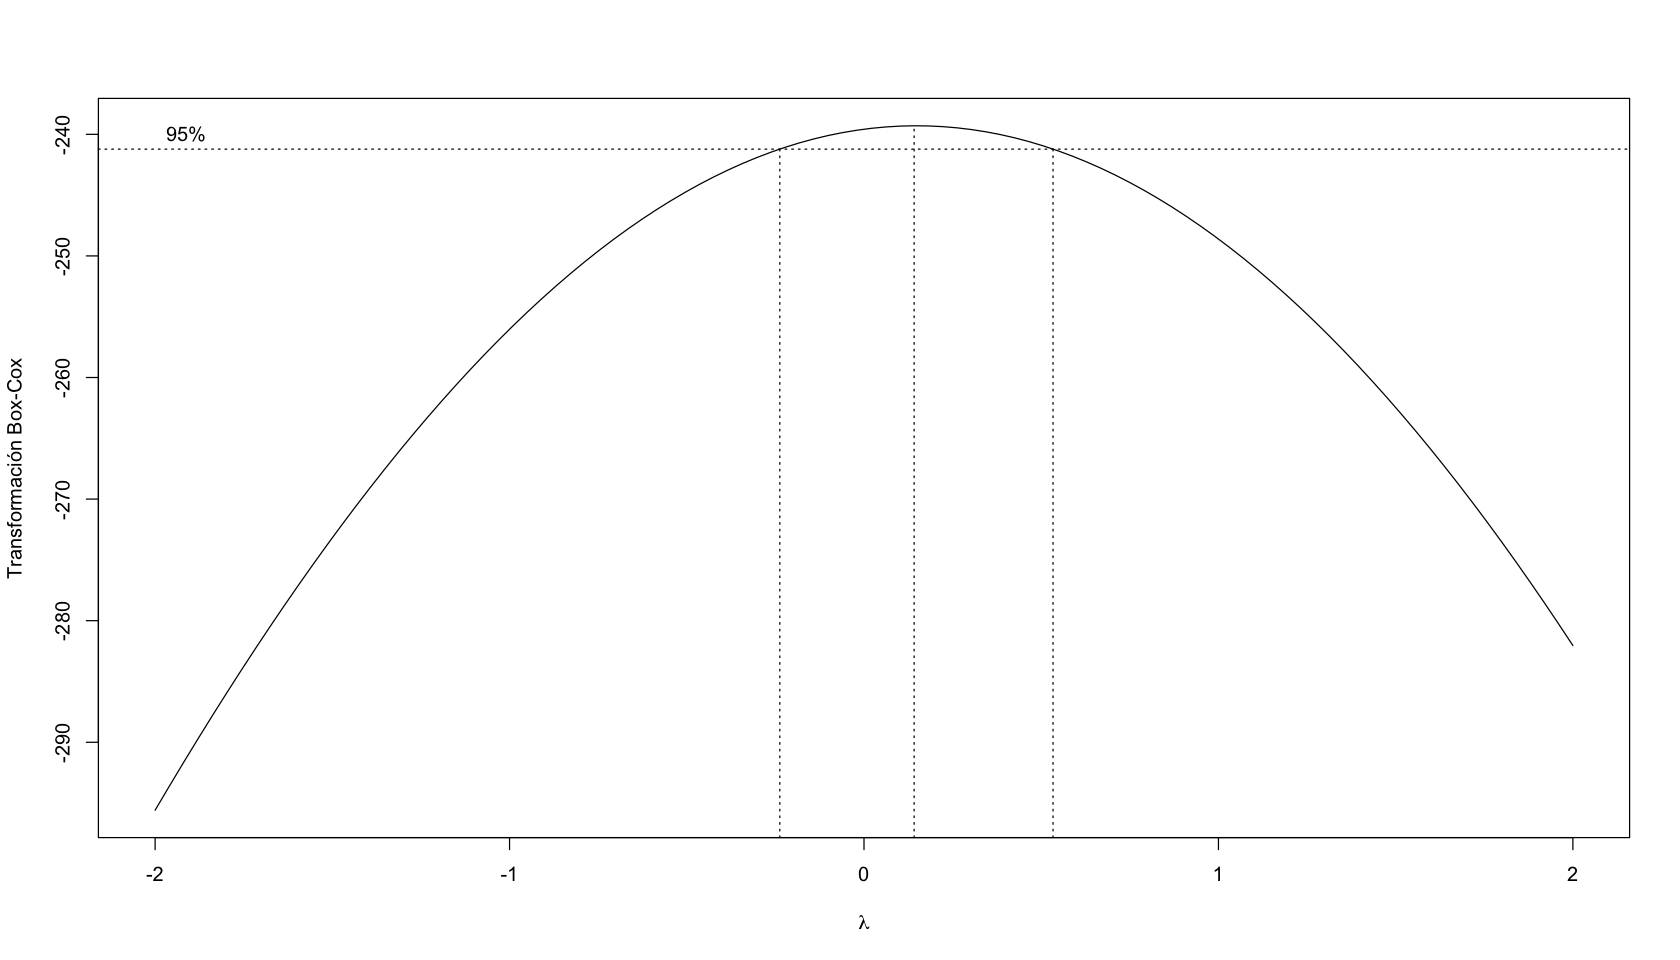

In [10]:
# Alternativa 2 (MASS) #
boxcox(pasaj ~ 1, lambda = seq(-2, 2, 1/10), plotit = TRUE, xlab = expression(lambda), ylab = "Transformación Box-Cox")

In [11]:
# Notemos que el valor de lambda es próximo a cero, por lo que realizamos una transformación logarítmica #
pasajt = log(pasaj)

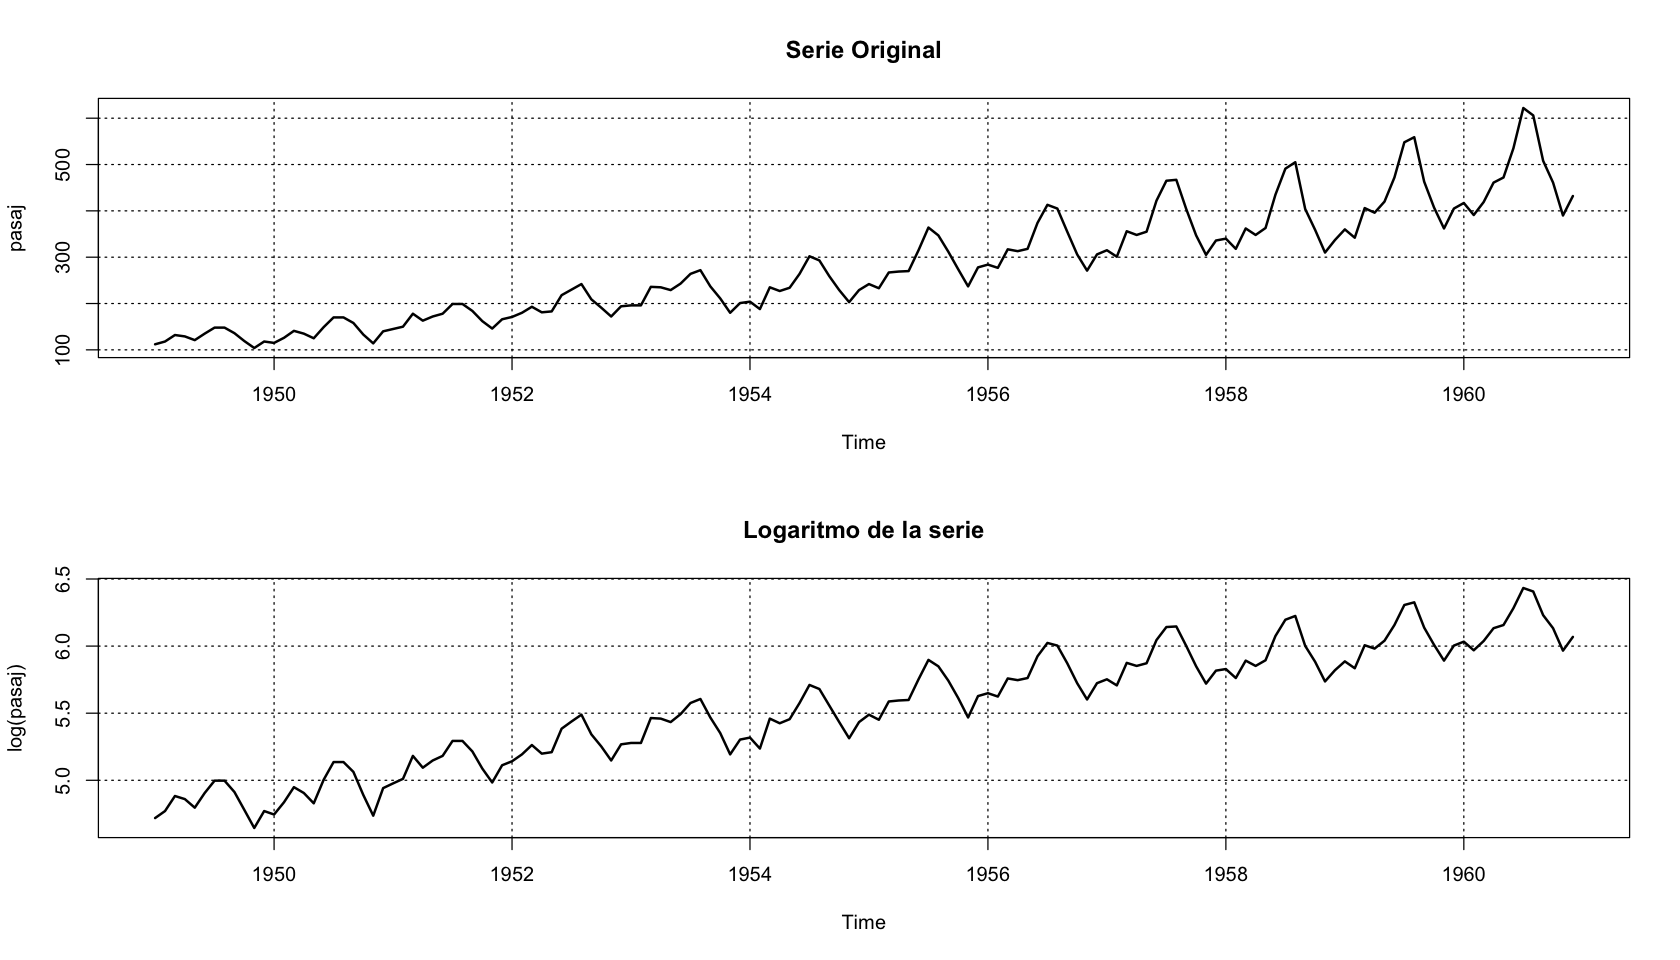

In [12]:
# Graficar serie original y en logarítmica #
par(mfrow=c(2,1))
plot(pasaj, main="Serie Original", lwd=2); grid(col = "black")
plot(log(pasaj), main="Logaritmo de la serie", lwd=2); grid(col = "black")

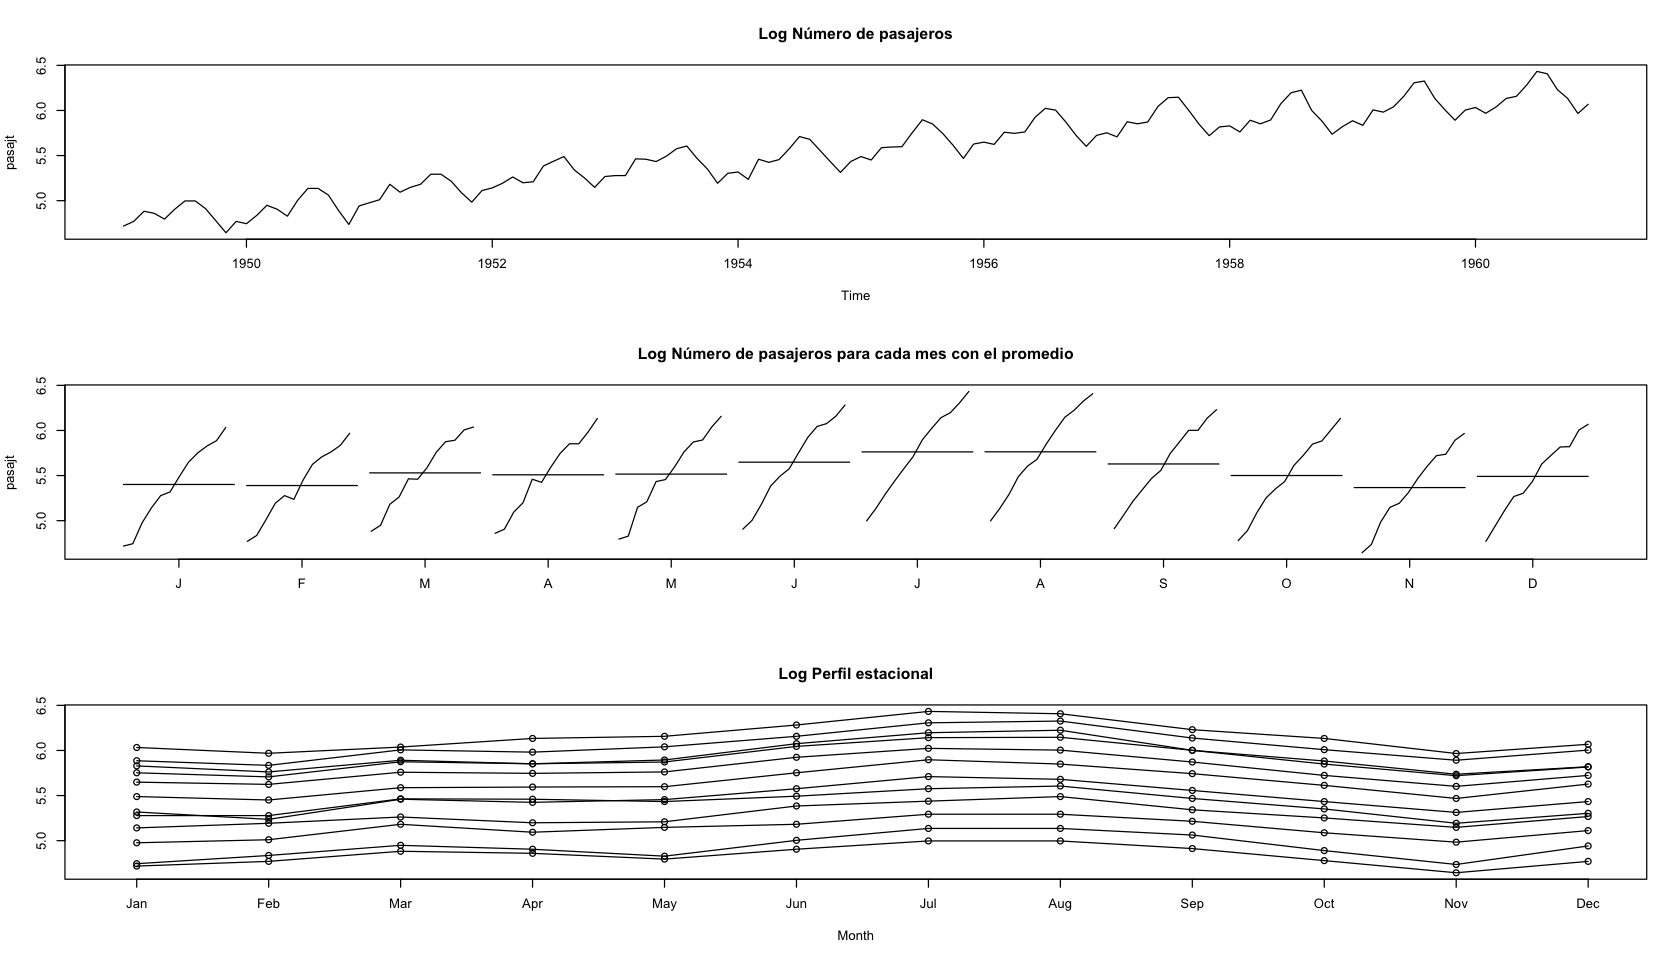

In [13]:
# Graficos estacionales #
par(mfrow=c(3,1))
ts.plot(pasajt,  main="Log Número de pasajeros")
monthplot(pasajt, main="Log Número de pasajeros para cada mes con el promedio")
seasonplot(pasajt, main="Log Perfil estacional")

## **Funciones de Autocorrelación y Autocorrelación Parcial**

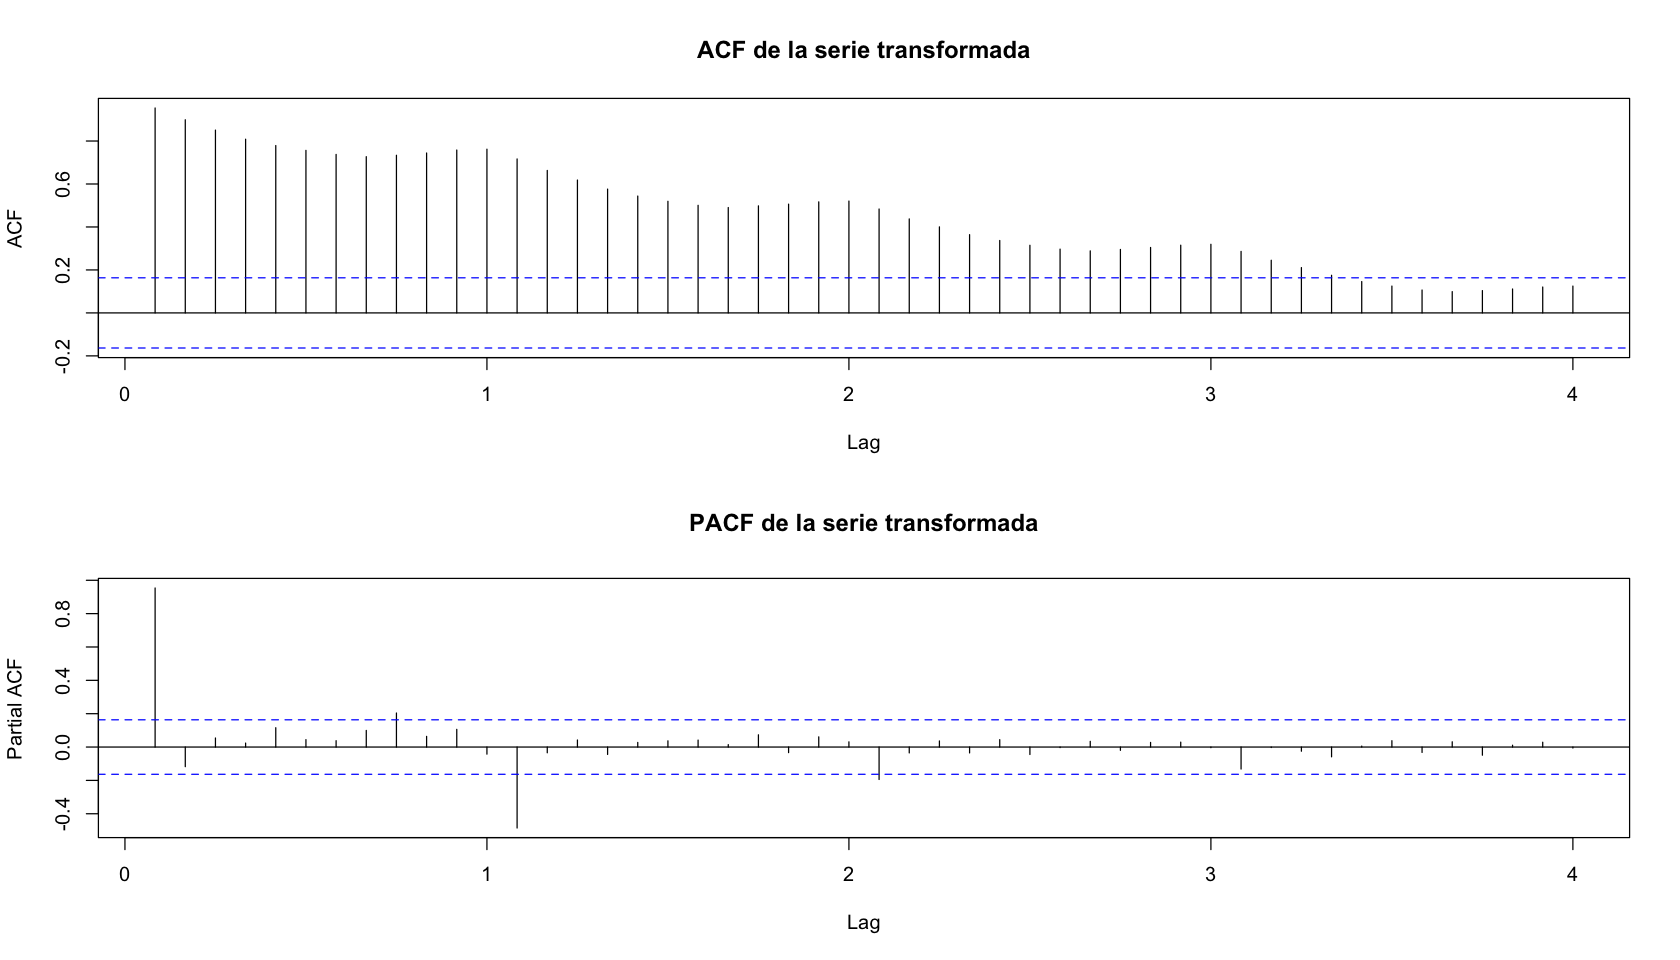

In [14]:
# ACF y PACF muestrales en un solo gráfico #
par(mfrow=c(2,1))
acf(pasajt, lag.max=48, main="ACF de la serie transformada")     # ACF hasta el rezago 48
pacf(pasajt, lag.max=48, main="PACF de la serie transformada")    # PACF hasta el rezago 48

# Alternativamente para obtener la ACF y PACF en un solo comando (astsa) #
#acf2(pasajt)

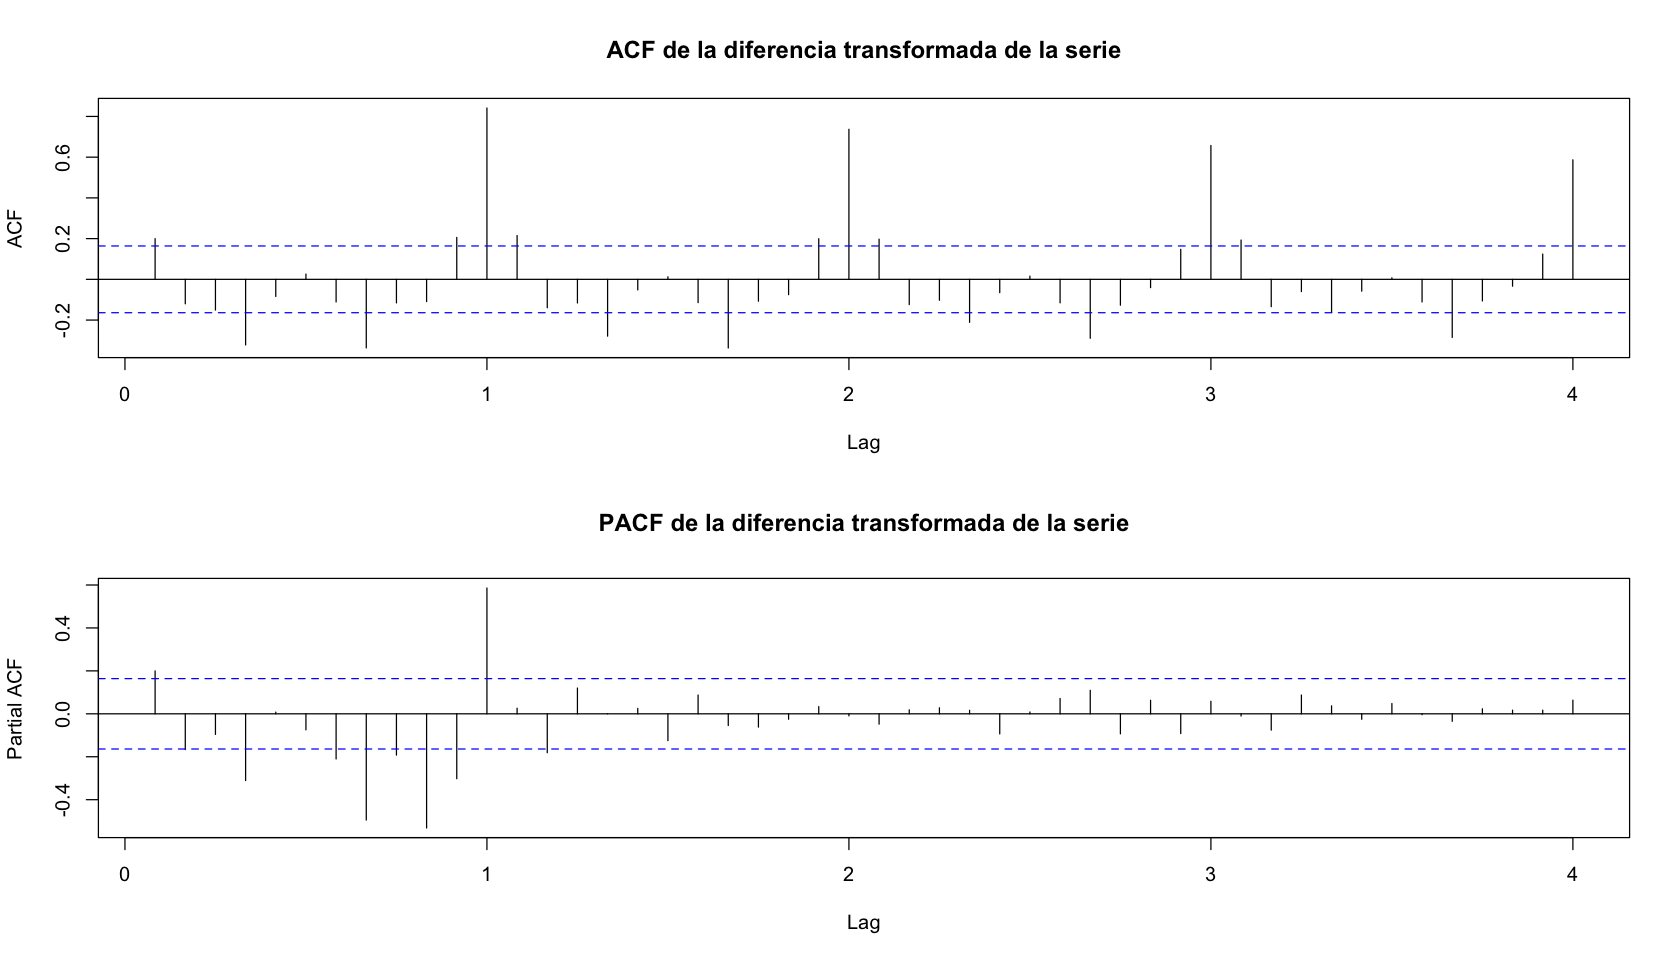

In [15]:
# ACF y PACF muestrales de la primera diferencia ordinaria, (1-B) #
par(mfrow=c(2,1))
acf(diff(pasajt), lag.max=48, main="ACF de la diferencia transformada de la serie")     # ACF hasta el rezago 48
pacf(diff(pasajt), lag.max=48, main="PACF de la diferencia transformada de la serie")    # PACF hasta el rezago 48

# Alternativamente para obtener la ACF y PACF en un solo comando (astsa) #
# acf2(diff(pasajt))

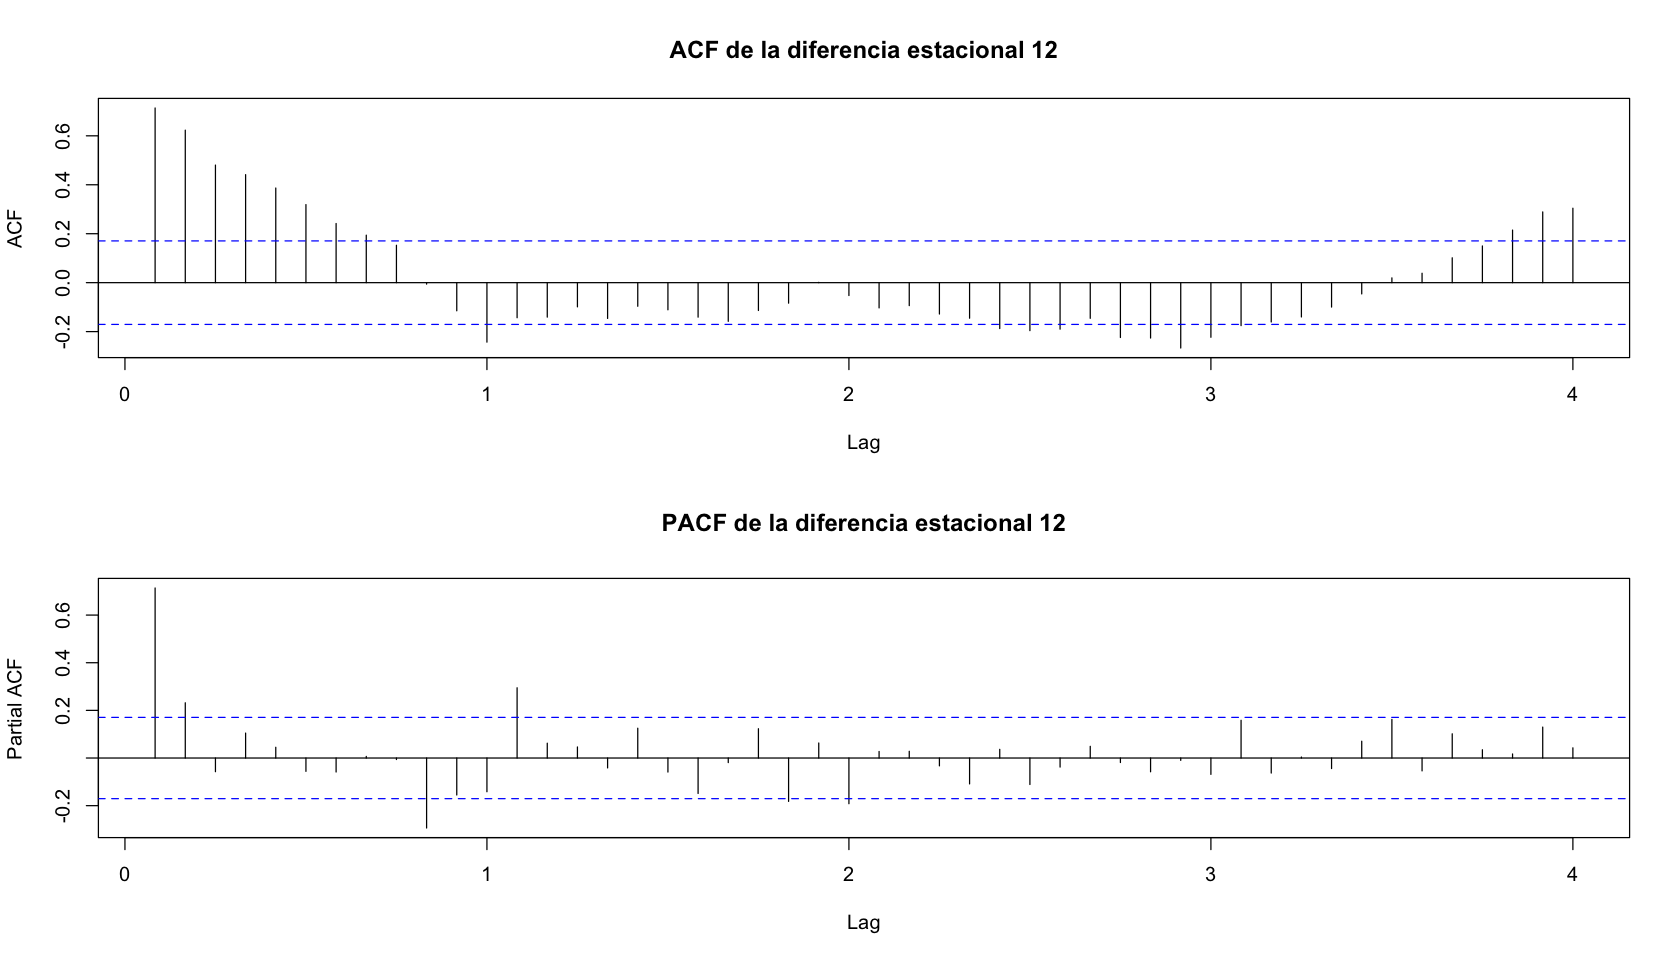

In [16]:
# ACF y PACF muestrales de la primera diferencia estacional (1-B^12) #
par(mfrow=c(2,1))
acf(diff(pasajt, lag=12), lag.max=48, main = "ACF de la diferencia estacional 12")     # ACF hasta el rezago 48
pacf(diff(pasajt, lag=12), lag.max=48, main = "PACF de la diferencia estacional 12")    # PACF hasta el rezago 48

# Alternativamente para obtener la ACF y PACF en un solo comando (astsa) #
# acf2(diff(pasajt, lag=12))

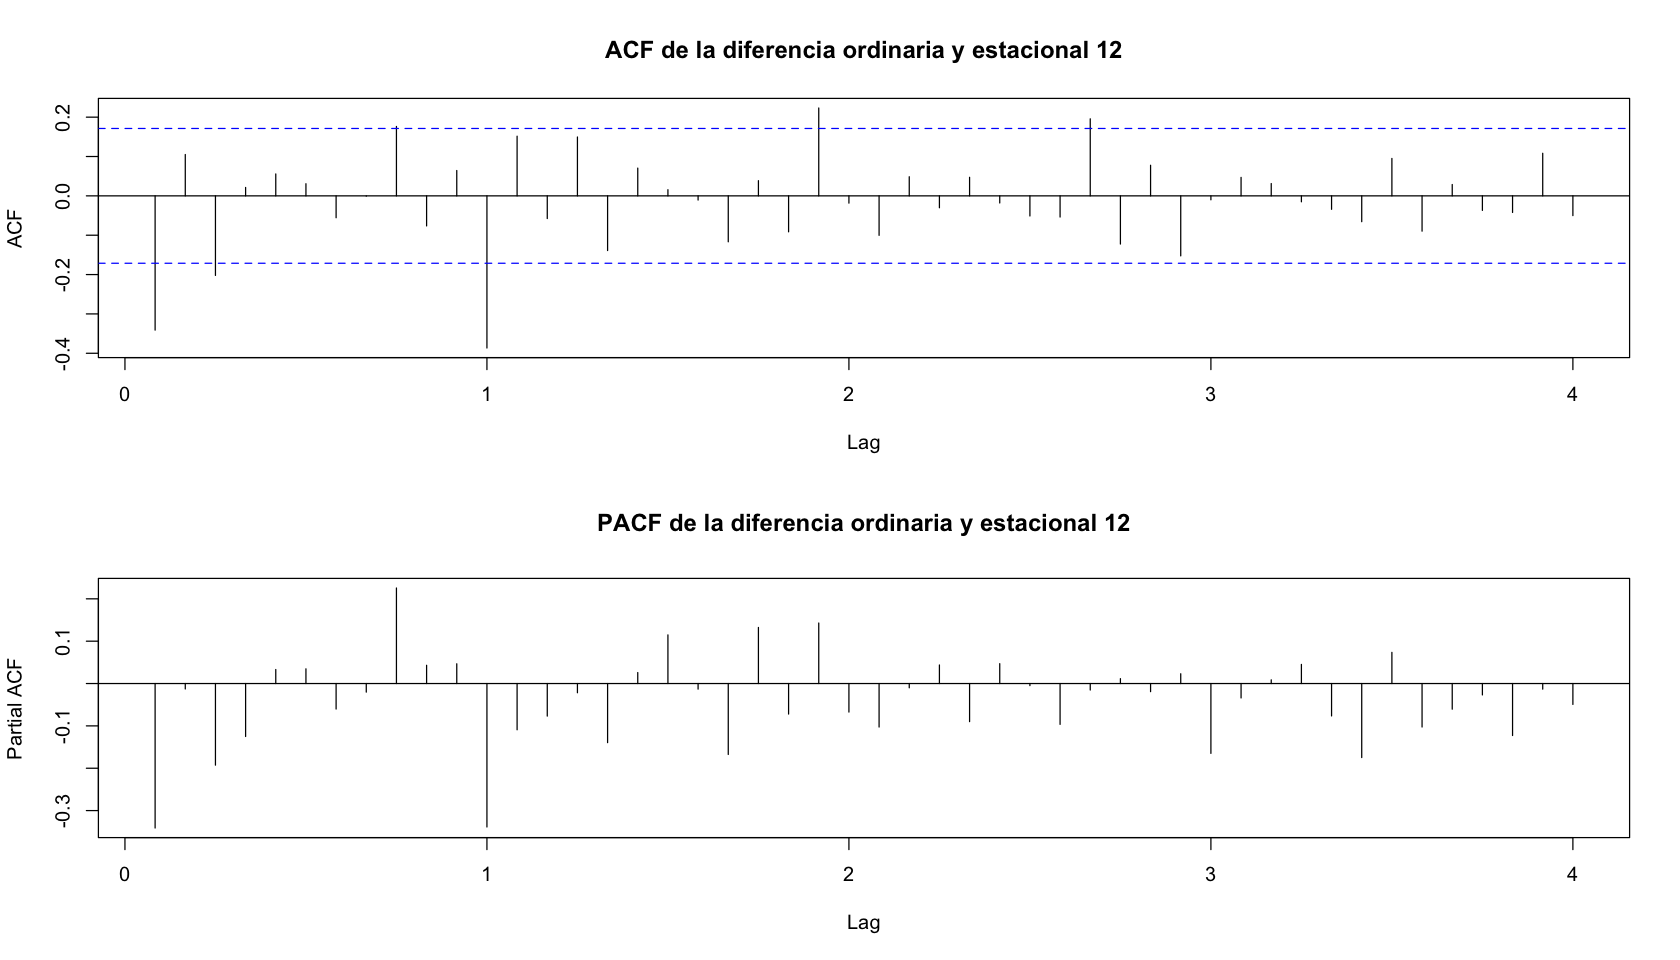

In [17]:
# ACF y PACF muestrales de (1-B)(1-B^12) #
d1pasajt = diff(pasajt)
par(mfrow = c(2,1))
acf(diff(d1pasajt, lag=12), 48, main = "ACF de la diferencia ordinaria y estacional 12")     # ACF hasta el rezago 48
pacf(diff(d1pasajt, lag=12), 48, ci=0, main = "PACF de la diferencia ordinaria y estacional 12")    # PACF hasta el rezago 48

## **Conclusión**: Hay evidencia de un $SARIMA(0,1,1)\times(0,1,1)_{12}$

---

## **Identificación con Criterios de Información**

In [18]:
# Función que busca modelos según los criterios de información AIC Y BIC #
p=1
q=1
P=1
Q=1

# Entre los ordenes de diferenciacion
d=1
D=1
(maxfilas=(p+1)*(q+1)*(P+1)*(Q+1))
ic_mod=matrix(rep(-99, times=maxfilas*6), nrow=maxfilas, ncol=6)

k=1
for(i in 0:p) {
for(j in 0:q) {
for(s in 0:P) {
for(m in 0:Q) {
modelo=Arima(pasajt, order = c(i, d, j),
     seasonal = list(order = c(s, D, m)), method = c("CSS-ML"))

     numpar=length(coef(modelo))
     T=length(residuals(modelo))
     ic_mod[k,1]=i
     ic_mod[k,2]=j
     ic_mod[k,3]=s
     ic_mod[k,4]=m
     ic_mod[k,5]=-2*(modelo$loglik/T)+(2*numpar)/T      # AIC
     ic_mod[k,6]=-2*(modelo$loglik/T)+(numpar*log(T))/T  # BIC
k=k+1
}
}
}
}
p_=ic_mod[,1]
q_=ic_mod[,2]
P_=ic_mod[,3]
Q_=ic_mod[,4]
AIC=ic_mod[,5]
BIC=ic_mod[,6]

[1] 16

In [19]:
# Tabla con ordenes de los modelos ajustados y los criterios de información #
(Crit_Inf = cbind(p_, q_, P_, Q_, AIC, BIC))

p_,q_,P_,Q_,AIC,BIC
0,0,0,0,-3.033541,-3.033541
0,0,0,1,-3.260820,-3.240197
0,0,1,0,-3.187634,-3.167010
0,0,1,1,-3.246971,-3.205724
0,1,0,0,-3.138746,-3.118122
0,1,0,1,-3.370827,-3.329579
0,1,1,0,-3.329204,-3.287956
0,1,1,1,-3.360508,-3.298637
1,0,0,0,-3.132042,-3.111418
1,0,0,1,-3.357567,-3.316319


In [20]:
# Ordenamiento del criterio de información AIC de menor a mayor #
Crit_Inf=data.frame(Crit_Inf)
(aic=Crit_Inf[order(Crit_Inf$AIC),])

,p_,q_,P_,Q_,AIC,BIC
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
6,0,1,0,1,-3.370827,-3.329579
8,0,1,1,1,-3.360508,-3.298637
14,1,1,0,1,-3.360413,-3.298542
10,1,0,0,1,-3.357567,-3.316319
16,1,1,1,1,-3.349381,-3.266886
12,1,0,1,1,-3.345345,-3.283474
7,0,1,1,0,-3.329204,-3.287956
15,1,1,1,0,-3.315739,-3.253868
11,1,0,1,0,-3.311242,-3.269995


In [21]:
# Ordenamiento del criterio de información BIC de menor a mayor #
(bic=Crit_Inf[order(Crit_Inf$BIC),])

,p_,q_,P_,Q_,AIC,BIC
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
6,0,1,0,1,-3.370827,-3.329579
10,1,0,0,1,-3.357567,-3.316319
8,0,1,1,1,-3.360508,-3.298637
14,1,1,0,1,-3.360413,-3.298542
7,0,1,1,0,-3.329204,-3.287956
12,1,0,1,1,-3.345345,-3.283474
11,1,0,1,0,-3.311242,-3.269995
16,1,1,1,1,-3.349381,-3.266886
15,1,1,1,0,-3.315739,-3.253868


## **Conclusión**: De nuevo hay evidencia de un $SARIMA(0,1,1)$ $\times$ $(0,1,1)_{12}$

## **Estimación**

In [22]:
# Especificación y estimación del modelo #
(mod = arima(pasajt, order = c(0, 1, 1), seasonal = list(order = c(0, 1, 1), period = 12), method = c("CSS-ML")))


Call:
arima(x = pasajt, order = c(0, 1, 1), seasonal = list(order = c(0, 1, 1), period = 12), 
    method = c("CSS-ML"))

Coefficients:
          ma1     sma1
      -0.4018  -0.5569
s.e.   0.0896   0.0731

sigma^2 estimated as 0.001348:  log likelihood = 244.7,  aic = -485.4

initial  value -3.086228 
iter   2 value -3.267980
iter   3 value -3.279950
iter   4 value -3.285996
iter   5 value -3.289332
iter   6 value -3.289665
iter   7 value -3.289672
iter   8 value -3.289676
iter   8 value -3.289676
iter   8 value -3.289676
final  value -3.289676 
converged
initial  value -3.286464 
iter   2 value -3.286855
iter   3 value -3.286872
iter   4 value -3.286874
iter   4 value -3.286874
iter   4 value -3.286874
final  value -3.286874 
converged
<><><><><><><><><><><><><><>
 
Coefficients: 
     Estimate     SE t.value p.value
ma1   -0.4018 0.0896 -4.4825       0
sma1  -0.5569 0.0731 -7.6190       0

sigma^2 estimated as 0.001348035 on 129 degrees of freedom 
 
AIC = -3.690069  AICc = -3.689354  BIC = -3.624225 
 


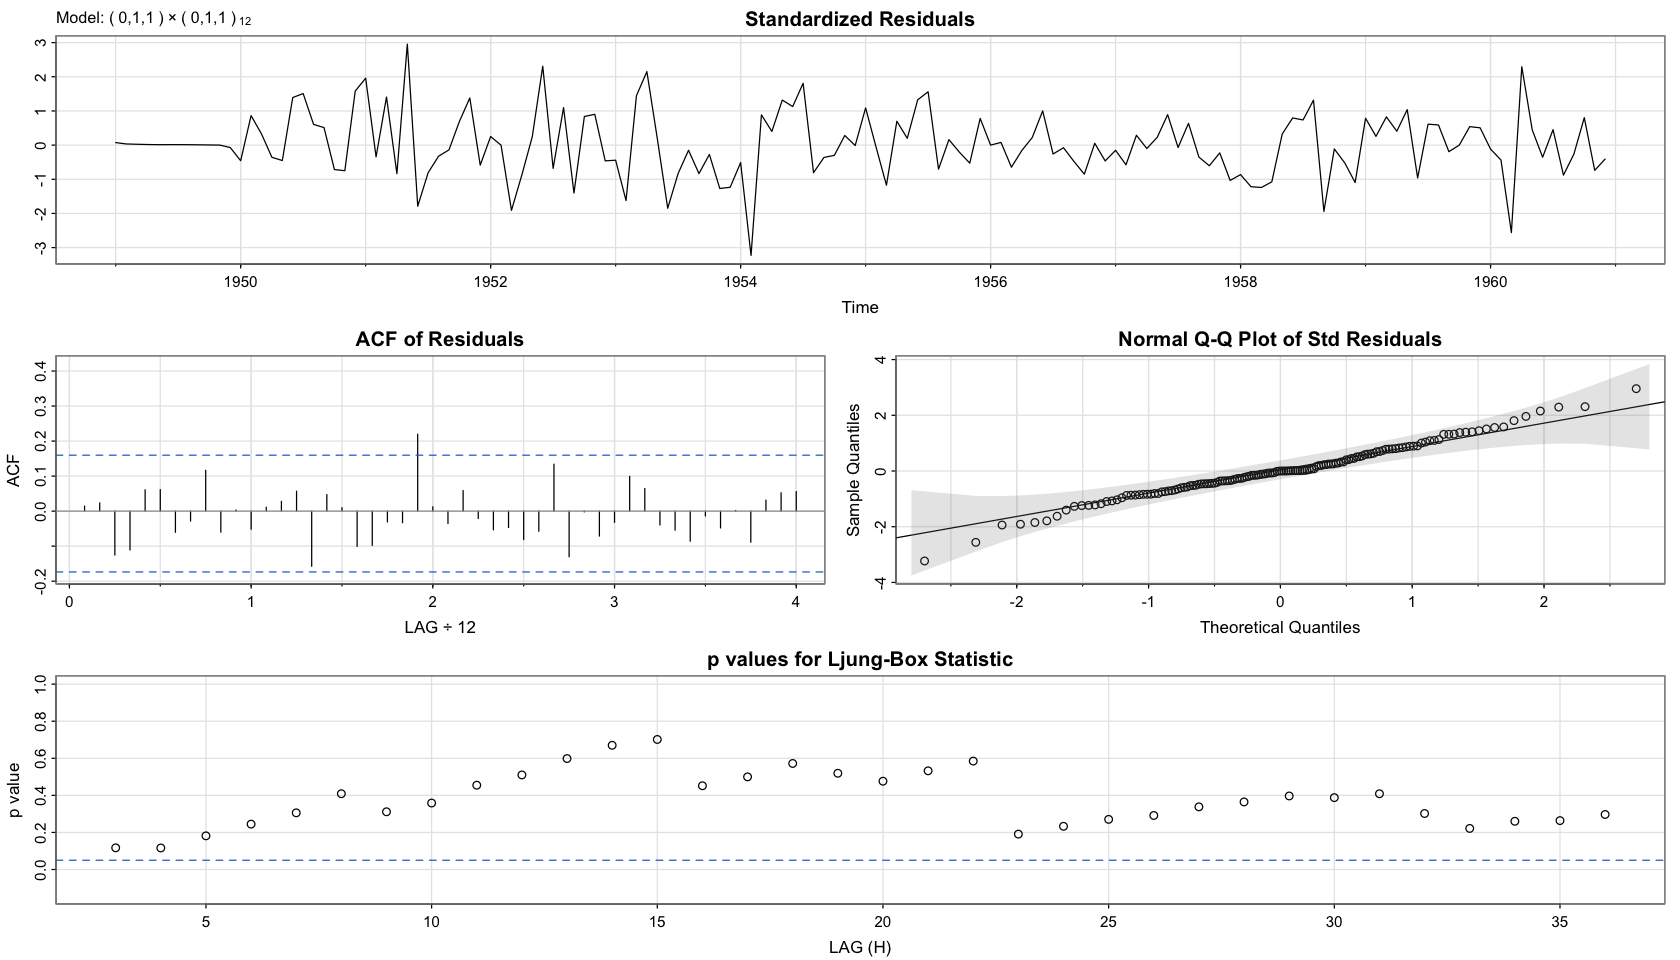

In [23]:
# Usando la función sarima() #
mod1 = sarima(pasajt, p=0, d=1, q=1, P = 0, D = 1, Q = 1, S = 12)

In [27]:
# Para mirar la significancia de las estimaciones #
mod1$ttable

NULL

In [30]:
# EJERCICIO : Autoarima, hacer pronósticos sin realizar tranformación #
aut = auto.arima(pasajt)
aut

Series: pasajt 
ARIMA(0,1,1)(0,1,1)[12] 

Coefficients:
          ma1     sma1
      -0.4018  -0.5569
s.e.   0.0896   0.0731

sigma^2 = 0.001371:  log likelihood = 244.7
AIC=-483.4   AICc=-483.21   BIC=-474.77

## **Diagnóstico residual**

In [31]:
# Ahora nos disponemos a evaluar el ajuste de los modelos #
res_mod = residuals(mod)

In [32]:
# Valores ajustados #
ajust = pasajt-res_mod

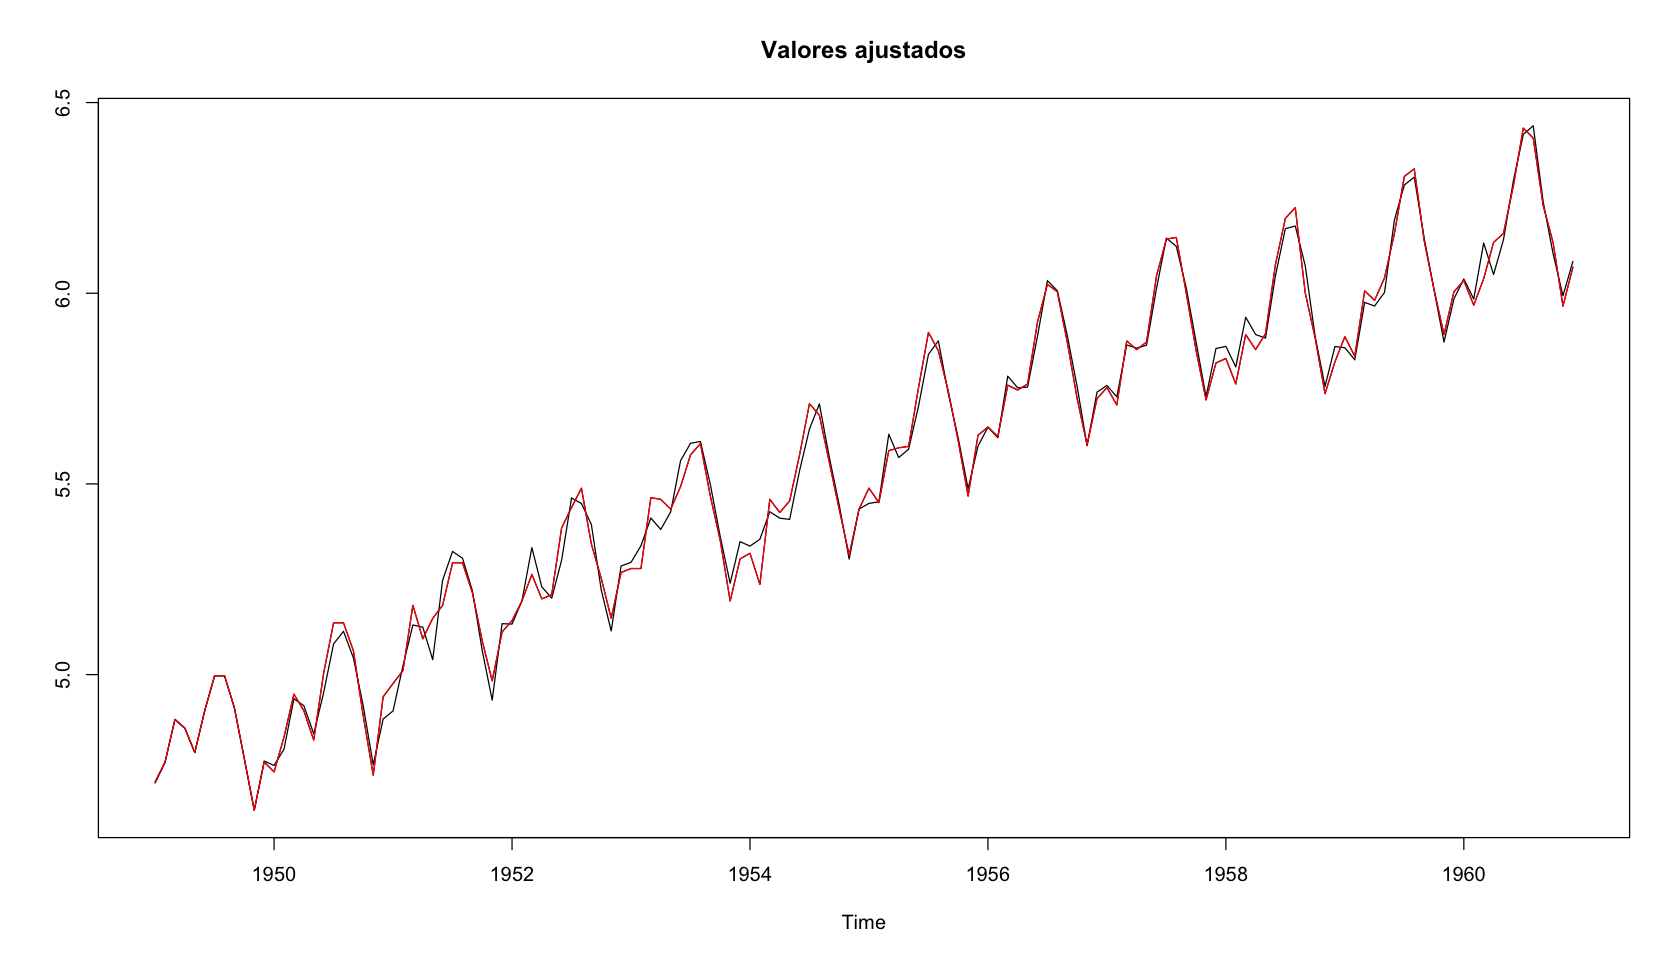

In [33]:
# Gráfico para los valores ajustados #
ts.plot(pasajt, ajust , main = "Valores ajustados")
lines(pasajt, col="red")

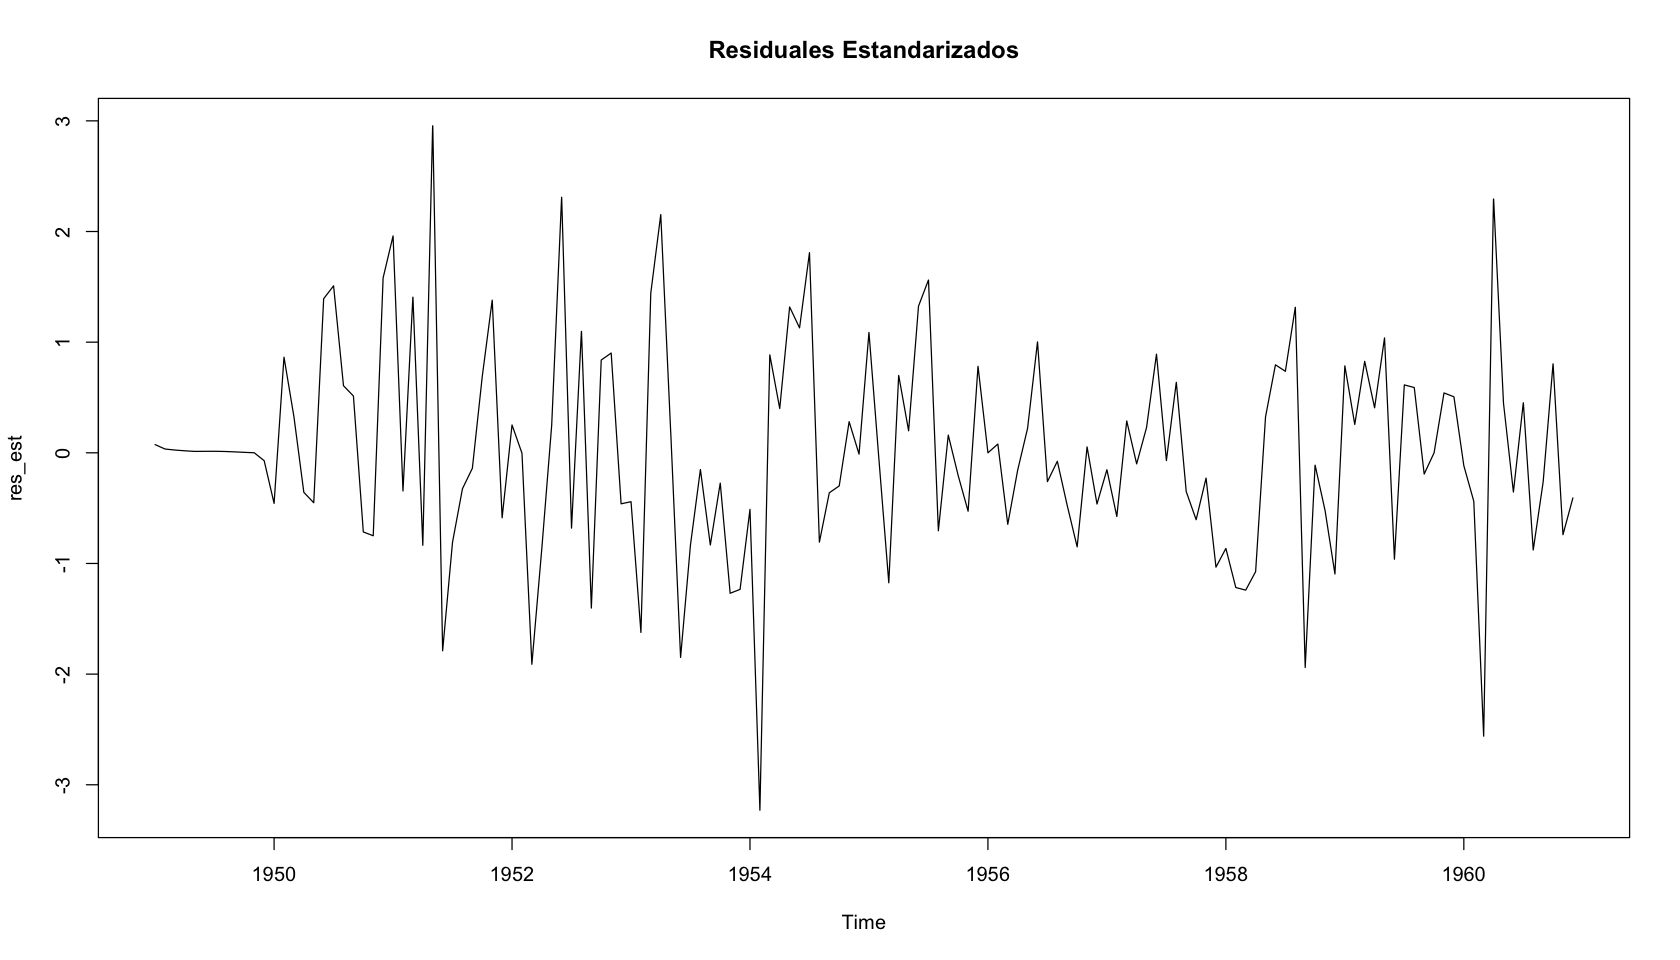

In [34]:
# Presentamos las gráficas residuales Estandarizados #
res_mod = residuals(mod)
res_est = res_mod/(mod$sigma2^.5)
plot.ts(res_est, main="Residuales Estandarizados")


	Box-Ljung test

data:  res_mod
X-squared = 0.030651, df = 1, p-value = 0.861


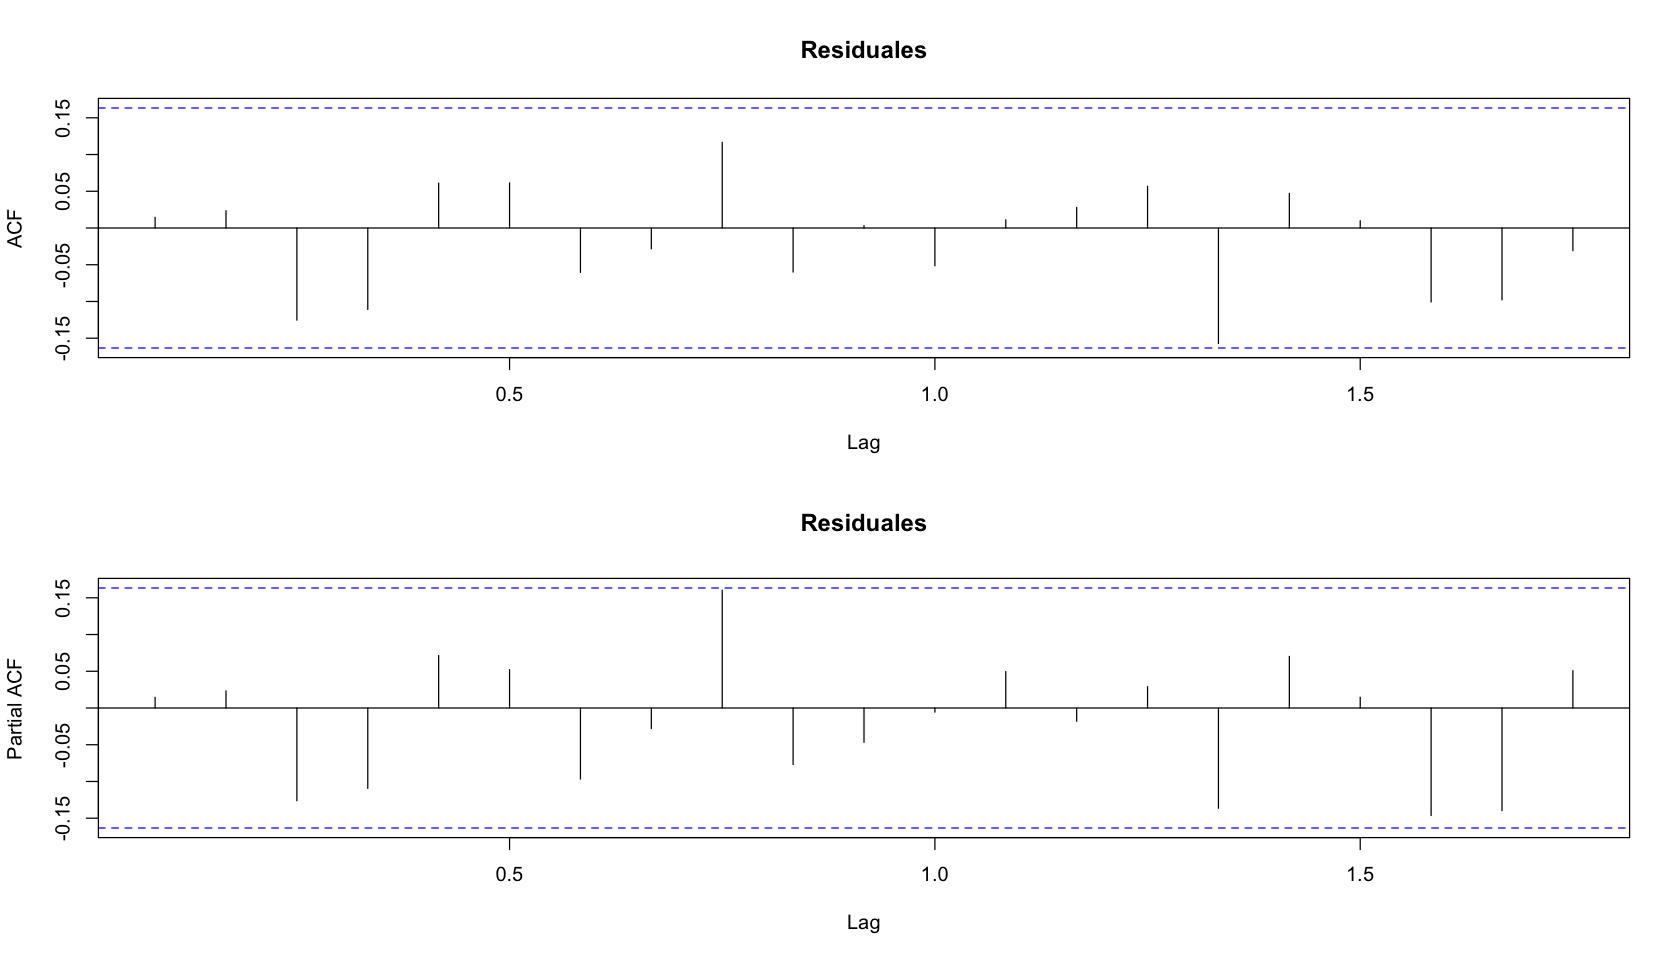

In [35]:
# ACF y PACF de residuales #
par(mfrow=c(2,1))
acf(res_mod, main = "Residuales")
pacf(res_mod, main= "Residuales")

# Prueba de Ljung-Box #
Box.test(res_mod, type = "Ljung-Box")

# Se encuentra evidencia para concluir que los residuales no están correlacionados #

## **Metodologías para Testear Normalidad**

In [36]:
# Shapiro Wilk: Prueba de Hipótesis para contrastar normalidad #
shapiro.test(res_mod)


	Shapiro-Wilk normality test

data:  res_mod
W = 0.98637, p-value = 0.1674


In [37]:
# Kolmogorov-Smirnov: Prueba no paramétrica basada en Bondad Ajuste #
lillie.test(res_mod)


	Lilliefors (Kolmogorov-Smirnov) normality test

data:  res_mod
D = 0.07772, p-value = 0.03307


In [38]:
# Jarque Bera: Basado en la Asimetría y Curtosis de una Normal #
jarqueberaTest(res_mod)


Title:
 Jarque-Bera Normality Test

Test Results:
  STATISTIC:
    X-squared: 5.2265
  P VALUE:
    Asymptotic p Value: 0.0733 


[1] 62 29

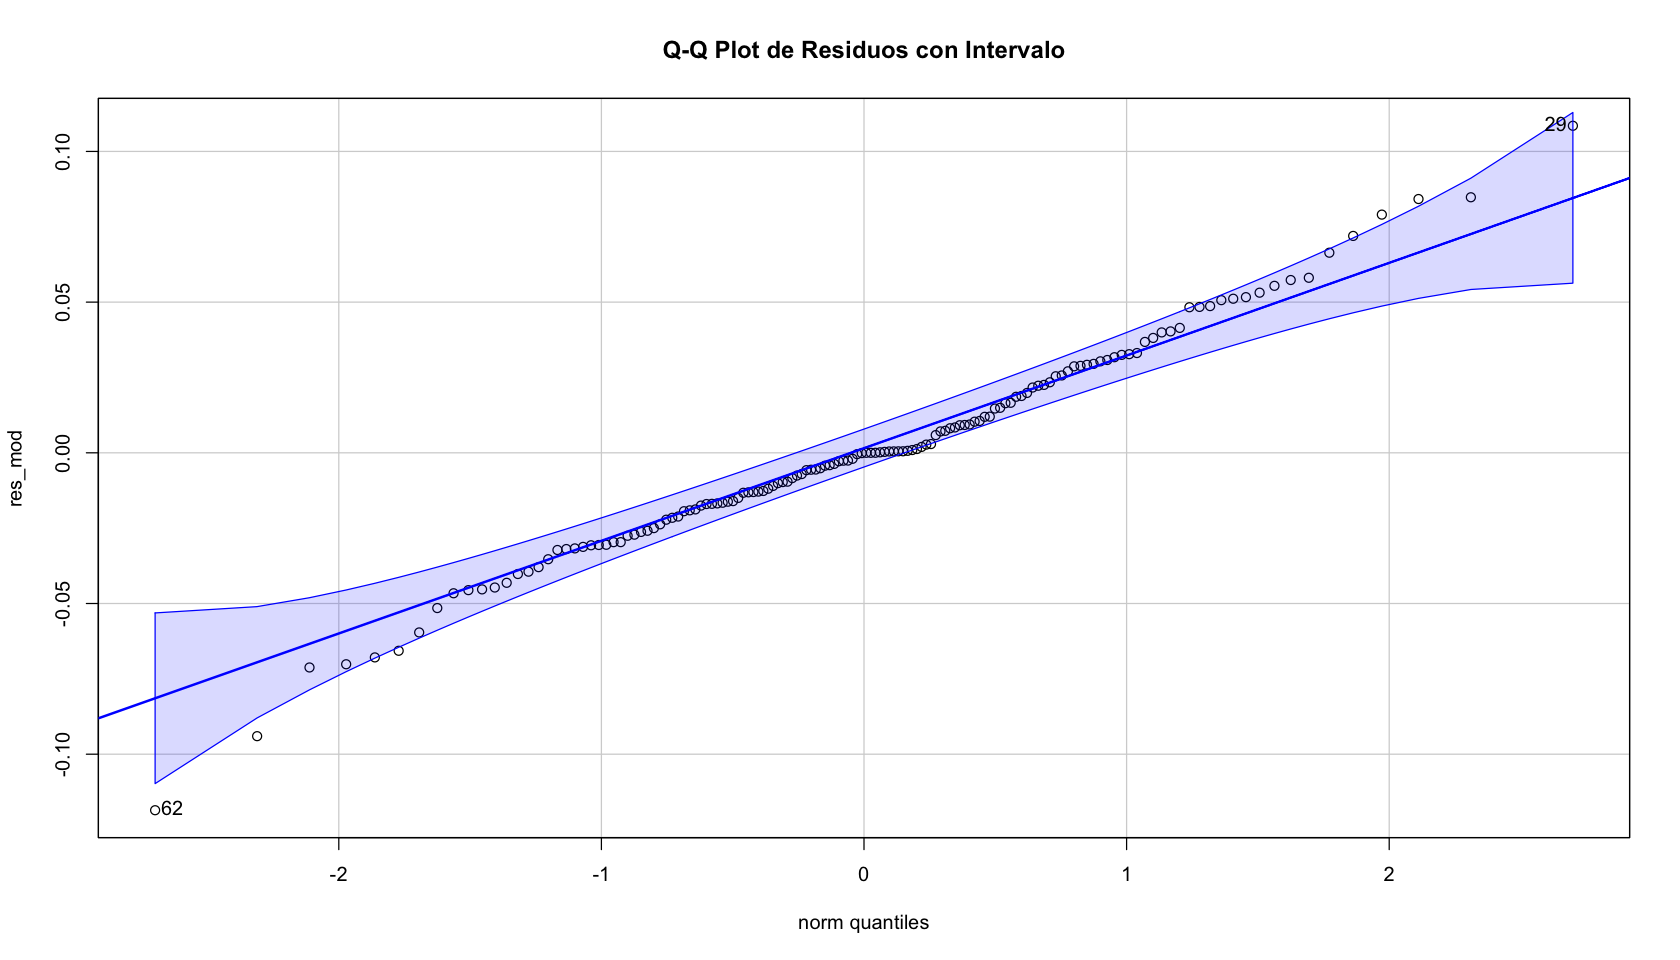

In [39]:
# Gráfico del Q-Q Plot #
qqPlot(res_mod, envelope = 0.95, main = "Q-Q Plot de Residuos con Intervalo") #library(car)

## **Pronósticos**

In [40]:
# Pronósticos para la serie transformada $
(pasajt.pred = predict(mod, n.ahead = 24, se.fit = TRUE))

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
1961,6.110186,6.053775,6.171715,6.199300,6.232556,6.368779,6.507294,6.502906,6.324698,6.209008,6.063487,6.168025
1962,6.206435,6.150025,6.267964,6.295550,6.328805,6.465028,6.603543,6.599156,6.420947,6.305257,6.159737,6.264274
,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
1961,0.03671562,0.04278291,0.04809072,0.05286831,0.05724857,0.06131671,0.06513125,0.06873441,0.07215788,0.07542612,0.07855852,0.08157071
1962,0.09008476,0.09549709,0.10061871,0.10549196,0.11014982,0.11461856,0.11891948,0.12307020,0.12708542,0.13097760,0.13475742,0.13843407


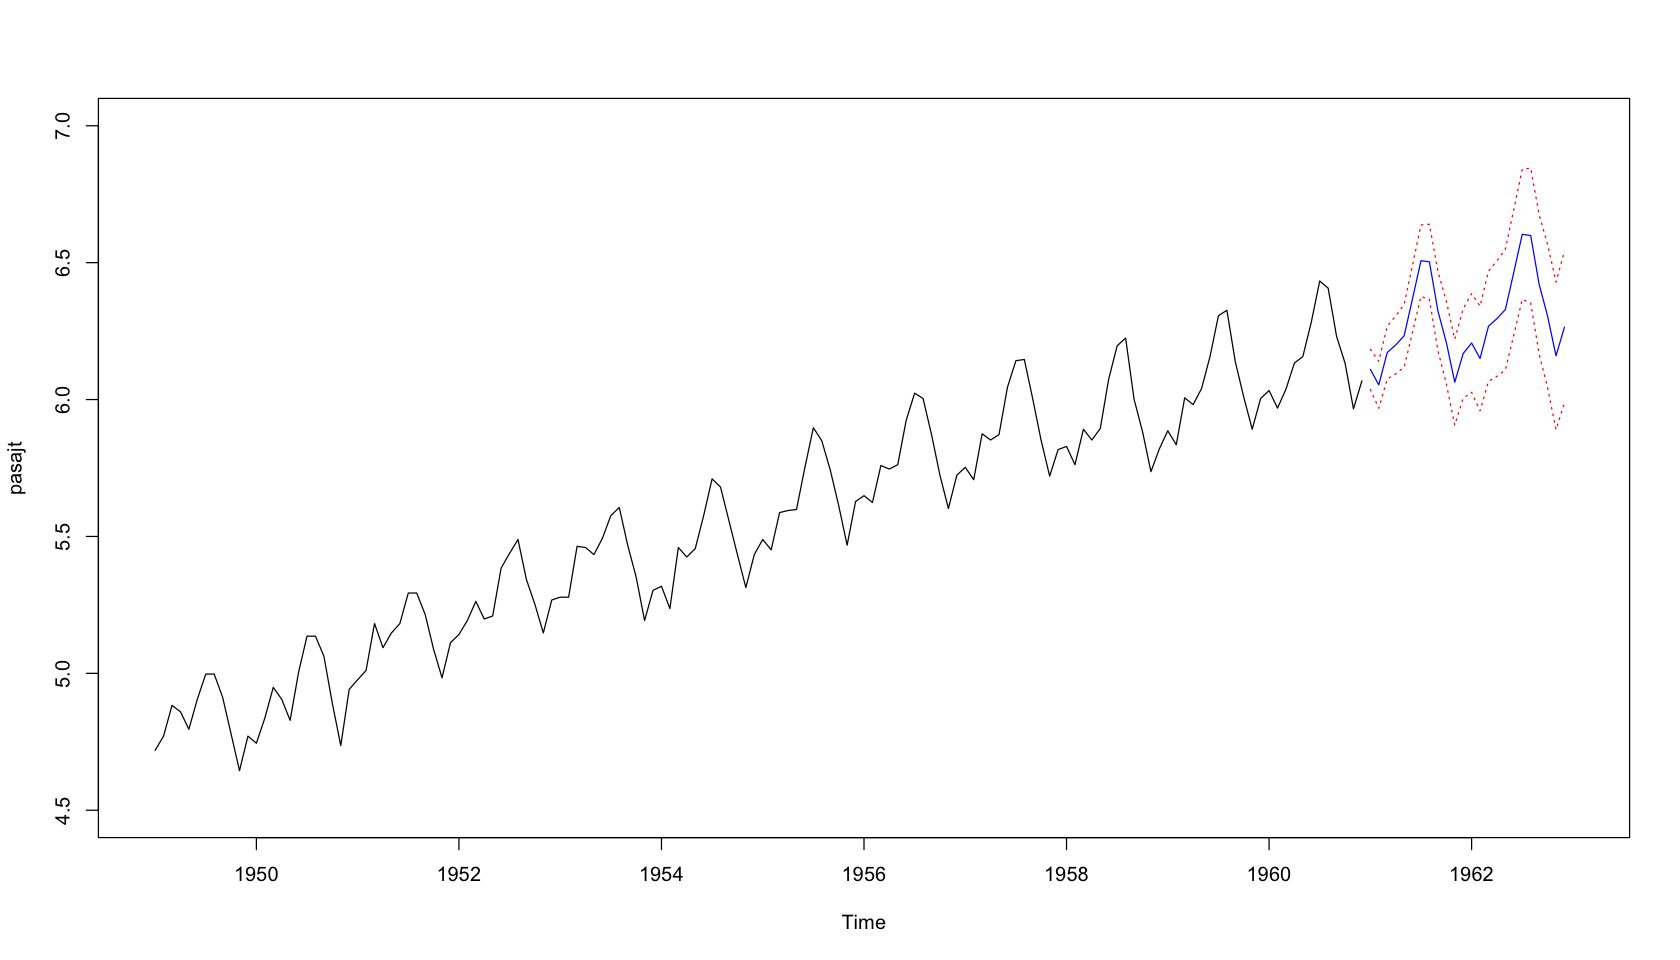

In [41]:
# Gráfico de los pronósticos con serie transfromada #
plot(pasajt,xlim=c(1949,1963), ylim=c(4.5,7))
pasajt.pred<-predict(mod,n.ahead=24)
lines(pasajt.pred$pred,col="blue")
lines(pasajt.pred$pred+2*pasajt.pred$se,col="red",lty=3)
lines(pasajt.pred$pred-2*pasajt.pred$se,col="red",lty=3)

In [42]:
# Intervalos de predicción para la serie transformada #
pronost = pasajt.pred$pred
stdev = pasajt.pred$se
liminft=pronost-2*stdev
limsupt=pronost+2*stdev

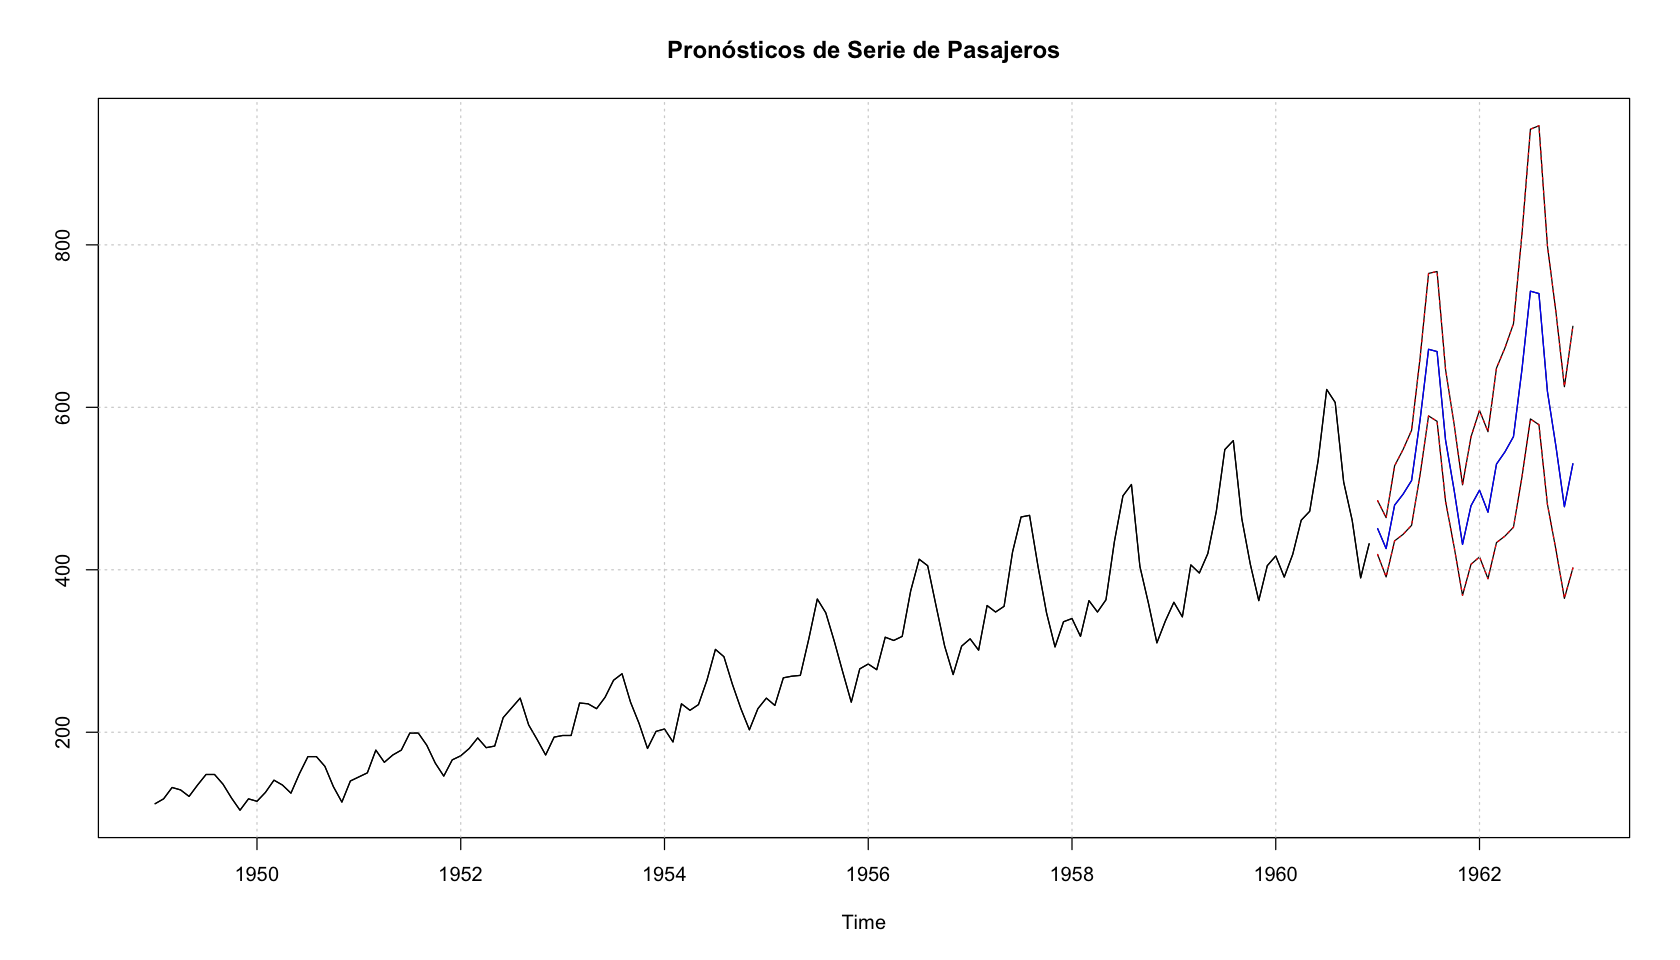

In [43]:
# Pronosticos e intervalos de prediccion para la serie original con correccion por sesgos de retransformacion #
pronos_orig=exp(pronost+.5*stdev^2)
liminf=exp(liminft+.5*stdev^2)
limsup=exp(limsupt+.5*stdev^2)
ts.plot(pasaj, pronos_orig, liminf, limsup, main="Pronósticos de Serie de Pasajeros"); grid()
lines(pasaj,col="black")
lines(pronos_orig,col="blue")
lines(liminf,col="red",lty=3)
lines(limsup,col="red",lty=3)

In [44]:
# Listado de los pron?sticos e intervalos de prediccion #
pronosticos = cbind(pronos_orig, liminf, limsup)
pronosticos

,pronos_orig,liminf,limsup
Jan 1961,450.7261,418.8147,485.0689
Feb 1961,426.1070,391.1631,464.1725
Mar 1961,479.5611,435.5849,527.9770
Apr 1961,493.0931,443.6169,548.0873
May 1961,509.8898,454.7271,571.7443
Jun 1961,584.4426,516.9908,660.6948
Jul 1961,671.4334,589.4279,764.8481
Aug 1961,668.6553,582.7742,767.1923
Sep 1961,559.6444,484.4363,646.5286
Oct 1961,498.6241,428.8042,579.8125


---
## **Ejercicio : Calcular el MAPE**

---
# 🎬 **¡FINAL!**
---